In [2]:
import keras
mnist = keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

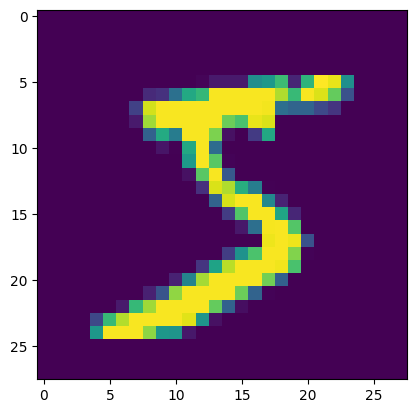

5


In [8]:
import matplotlib.pyplot as plt
plt.imshow(x_train[0]) #training image
plt.show()
print(y_train[0]) #what the number is supposed to be

In [10]:
#Reshape the data
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1) #0 is for the first picture,28 28 is for size and 1 is for color
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)
input_shape = (28, 28, 1)

#Normalize the pixel values from a scale out of 255 to a scale out of 1
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

In [12]:
print(y_train[0])

y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

print(y_train[0]) #5 meaning the position of the class the train value appear

5
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [14]:
model = keras.models.Sequential()
model.add(keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu',
                              input_shape=input_shape))

model.add(keras.layers.Conv2D(64, (3, 3), activation='relu'))
model.add(keras.layers.MaxPooling2D(pool_size=(2, 2)))
model.add(keras.layers.Dropout(0.25))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(128, activation='relu'))
model.add(keras.layers.Dropout(0.5))
model.add(keras.layers.Dense(10, activation='softmax'))

C:\Users\user\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
model.compile(loss=keras.losses.categorical_crossentropy,
              optimizer=keras.optimizers.Adadelta(),
              metrics=['accuracy'])

model.fit(x_train, y_train,
          batch_size=128,
          epochs=30,
          validation_data=(x_test, y_test))

Epoch 1/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 58s 120ms/step - accuracy: 0.8454 - loss: 0.5053 - val_accuracy: 0.9049 - val_loss: 0.3404
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 54s 116ms/step - accuracy: 0.8459 - loss: 0.5016 - val_accuracy: 0.9063 - val_loss: 0.3364
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 118ms/step - accuracy: 0.8488 - loss: 0.4943 - val_accuracy: 0.9078 - val_loss: 0.3315
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - accuracy: 0.8493 - loss: 0.4919 - val_accuracy: 0.9076 - val_loss: 0.3279
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - accuracy: 0.8518 - loss: 0.4846 - val_accuracy: 0.9094 - val_loss: 0.3240
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 118ms/step - accuracy: 0.8558 - loss: 0.4767 - val_accuracy: 0.9093 - val_loss: 0.3202
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 55s 117ms/step - accuracy: 0.8554 - loss: 0.4730 - val_accuracy: 0.9111 - val_loss: 0.3163
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 119ms/step - accuracy: 0.8584 - loss: 0

In [38]:
print(model.evaluate(x_test, y_test))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9248 - loss: 0.2586
[0.2585776150226593, 0.9247999787330627]


In [40]:
loss, acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {acc * 100:.2f}%")


Test Loss: 0.2586
Test Accuracy: 92.48%
